# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Мартин Максим'   # прізвище та ім'я
GROUP        = 'ШІ-31'           # шифр групи, наприклад СШІ-31
NUMBER       = 14                # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Мартин Максим | ШІ-31 | номер 14


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 14   ·   Мартин Максим   ·   ШІ-31

   Ринок:  Zhytomyr
   Товар:  молоко   (у наборі даних: Milk - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
## Підготовка середовища

Бібліотеки, стиль графіків і параметри, які задані умовою жорстко (сітка, 7 фолдів × 3 кроки, ARIMA(1,1,1)).
Файли `ціни_україна_2014_2017.csv` і `lr4_variants_student.json` мають лежати поруч із зошитом
(у Colab — завантажити в панель «Файли» зліва). Графіки додатково зберігаються в папку `figures/`.

In [3]:
# Підготовка: бібліотеки, стиль графіків і параметри, задані умовою
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from scipy.signal import argrelextrema
from sklearn.model_selection import train_test_split
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings('ignore')  # прибираємо технічні попередження statsmodels (збіжність, межі p у KPSS)

# Параметри, задані умовою (мають збігатися з Orange)
START, END = '2014-03-01', '2017-12-01'   # повна місячна сітка: 46 місяців
N_FOLDS, H = 7, 3                         # 7 фолдів по 3 місяці
ORDER = (1, 1, 1)                         # порядок ARIMA для порівняння з Orange
UNIT = 'грн/л'
MONTHS_UA = ['січ', 'лют', 'бер', 'кві', 'тра', 'чер', 'лип', 'сер', 'вер', 'жов', 'лис', 'гру']

# Кольори та стиль графіків (однакові в усій роботі)
BLUE, ORANGE, RED, GRAY, INK = '#2a78d6', '#eb6834', '#e34948', '#898781', '#0b0b0b'
plt.rcParams.update({
    'figure.figsize': (11, 3.8), 'font.size': 10, 'font.family': 'DejaVu Sans',
    'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.8,
    'axes.edgecolor': '#c3c2b7', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
})
os.makedirs('figures', exist_ok=True)

def show(fig, name):
    """Зберігає графік у figures/<name>.png (для звіту) і показує його в зошиті."""
    fig.tight_layout()
    fig.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

print('Готово: бібліотеки завантажено, фолдів', N_FOLDS, '× кроків', H, '| ARIMA', ORDER)

Готово: бібліотеки завантажено, фолдів 7 × кроків 3 | ARIMA (1, 1, 1)


---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [4]:
# Завдання 1. Підготовка ряду
prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices['date'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))

# Вибираємо свій ряд: один ринок, один товар
raw = (prices[(prices['ринок'] == MARKET) & (prices['товар'] == GOOD)]
       .sort_values('date').set_index('date')['ціна'])
unit = prices.loc[prices['товар'] == GOOD, 'одиниця'].iloc[0]
print(f'Записів для {MARKET} · {GOOD}: {len(raw)} (одиниця: {unit}, валюта: UAH)')
assert raw.index.is_unique, 'на один місяць не може бути двох записів'

# Повна місячна сітка: перше число кожного місяця з 03.2014 по 12.2017
grid = pd.date_range(START, END, freq='MS')
y_raw = raw.reindex(grid)                       # місяць без запису стає NaN — пропуск стає видимим
gap = y_raw[y_raw.isna()].index
print(f'Місяців у сітці: {len(grid)} | з виміром: {y_raw.notna().sum()} | пропусків: {len(gap)}')
print('Пропущений місяць:', ', '.join(d.strftime('%m.%Y') for d in gap))

# Чому виник пропуск: рахуємо записи кожного місяця в УСЬОМУ наборі (усі ринки, усі товари)
rows_per_month = prices.groupby('date').size().reindex(grid, fill_value=0)
empty = rows_per_month[rows_per_month == 0].index
print('Місяці без жодного запису в усьому наборі:', ', '.join(d.strftime('%m.%Y') for d in empty))
print(f'Для порівняння: у звичайний місяць у наборі {int(rows_per_month.median())} записів')

Записів для Zhytomyr · Milk - Retail: 45 (одиниця: L, валюта: UAH)
Місяців у сітці: 46 | з виміром: 45 | пропусків: 1
Пропущений місяць: 08.2017
Місяці без жодного запису в усьому наборі: 08.2017
Для порівняння: у звичайний місяць у наборі 649 записів


**Висновок до завдання 1:**

Сітка 03.2014–12.2017 має **46 місяців**, вимір є для **45**. Пропуск один — **серпень 2017 (08.2017)**.

Причина не в нашому ряді: у **всьому наборі** за серпень 2017 немає жодного запису (у звичайний місяць їх ~649). Тобто цей місяць не потрапив у джерело (база WFP) ні для одного ринку й товару — пропуск системний. У нашому ряді він **один**.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [5]:
# Завдання 2. Заповнення пропуску
g = gap[0]                                        # 2017-08-01 — єдиний пропуск
prev = y_raw[g - pd.DateOffset(months=1)]         # липень 2017
nxt = y_raw[g + pd.DateOffset(months=1)]          # вересень 2017

# Спосіб 3 (власний): лінійна інтерполяція + «сезонна поправка серпня».
# Дивимось, на скільки серпень відхилявся від середнього липня й вересня у 2014–2016 рр.
aug_shift = [y_raw[f'{yr}-08-01'] - (y_raw[f'{yr}-07-01'] + y_raw[f'{yr}-09-01']) / 2
             for yr in (2014, 2015, 2016)]

fills = pd.Series({
    '1) перенесення останнього (ffill)': y_raw.ffill()[g],
    '2) лінійна інтерполяція':           y_raw.interpolate(method='linear')[g],
    '3) лінійна + сезонна поправка':     y_raw.interpolate(method='linear')[g] + np.mean(aug_shift),
    '4) кубічний сплайн':                y_raw.interpolate(method='spline', order=3)[g],
}).round(3)
print(f'Сусіди пропуску: липень {prev:.3f}, вересень {nxt:.3f} {UNIT}')
print('Відхилення серпня від сусідів у 2014, 2015, 2016:', np.round(aug_shift, 3),
      f'→ середнє {np.mean(aug_shift):+.3f}')
print('\nЗначення для 08.2017, ' + UNIT)
print(fills.to_string())

# Обраний спосіб — лінійна інтерполяція. Далі вся робота йде з рядом y.
y = y_raw.interpolate(method='linear')
y.name = 'price'
assert len(y) == 46 and y.notna().all()
print(f'\nОбрано лінійну інтерполяцію: 08.2017 = {y[g]:.4f} {UNIT}')

# Коли заповнювати НЕ можна: ринки, що випадають із набору у 2014 р.
print('\nРинки з довгими пропусками (принцип, а не наш ряд):')
months_with_data = prices.groupby('ринок')['date'].nunique()
for m in months_with_data[months_with_data < 45].index:
    have = set(prices.loc[prices['ринок'] == m, 'date'])
    miss2014 = [d.strftime('%m.%Y') for d in grid if d not in have and d.year == 2014]
    if len(have) <= 2:
        print(f'  {m:14s} даних {len(have):2d} міс. із 46 → після {max(have):%m.%Y} ряд обривається назавжди')
    else:
        print(f'  {m:14s} даних {len(have):2d} міс. із 46 → пропуски 2014 р.: {", ".join(miss2014)}')

Сусіди пропуску: липень 15.710, вересень 16.063 грн/л
Відхилення серпня від сусідів у 2014, 2015, 2016: [ 0.208  0.027 -0.458] → середнє -0.074

Значення для 08.2017, грн/л
1) перенесення останнього (ffill)    15.710
2) лінійна інтерполяція              15.887
3) лінійна + сезонна поправка        15.812
4) кубічний сплайн                   16.088

Обрано лінійну інтерполяцію: 08.2017 = 15.8867 грн/л

Ринки з довгими пропусками (принцип, а не наш ряд):
  Crimea         даних  1 міс. із 46 → після 03.2014 ряд обривається назавжди
  Donetska       даних 42 міс. із 46 → пропуски 2014 р.: 08.2014, 09.2014, 12.2014
  Luhanska       даних 40 міс. із 46 → пропуски 2014 р.: 08.2014, 09.2014, 10.2014, 11.2014, 12.2014
  m. Sevastopol  даних  2 міс. із 46 → після 04.2014 ряд обривається назавжди


**Висновок до завдання 2:**

| спосіб | значення 08.2017, грн/л |
|---|---|
| перенесення останнього (ffill) | 15.710 |
| **лінійна інтерполяція** | **15.887** |
| лінійна + сезонна поправка | 15.812 |
| кубічний сплайн | 16.088 |

**Обрано лінійну інтерполяцію.** Пропуск один і стоїть між двома відомими сусідами (липень 15.71, вересень 16.06), тож середина між ними — найпростіша й найчесніша оцінка. Перенесення ігнорує вересень і занижує значення на ряді, що росте. Сезонна поправка ненадійна: у 2014–2016 рр. серпень відхилявся від сусідів то вгору (+0.21, +0.03), то вниз (−0.46) — стабільного «серпневого ефекту» немає. Сплайн дає 16.09, тобто **вище** за вересень, — вигадує пік, якого не було. До того ж лінійну інтерполяцію має й віджет Interpolate в Orange.

**Коли заповнювати не можна:** коли пропуск довгий і викликаний подією, яка змінила саму реальність. У цьому ж наборі **Крим** (є лише 03.2014) і **Севастополь** (03–04.2014) після анексії зникають назавжди, а **Луганська область** не має даних за 08–12.2014 — період бойових дій. «Заповнити» такі ряди означало б вигадати ціни там, де їх ніхто не спостерігав, і саме тоді, коли вони, найімовірніше, поводилися ненормально. Тут сам пропуск — це інформація: його залишають або виключають ринок з аналізу.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

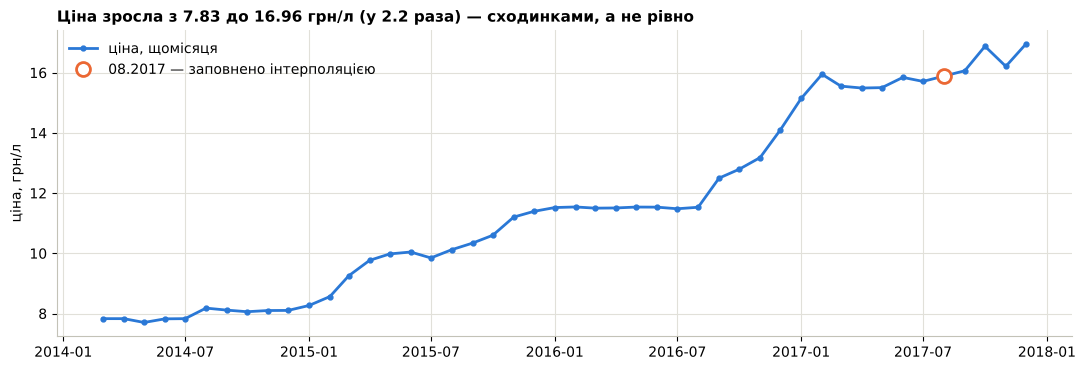

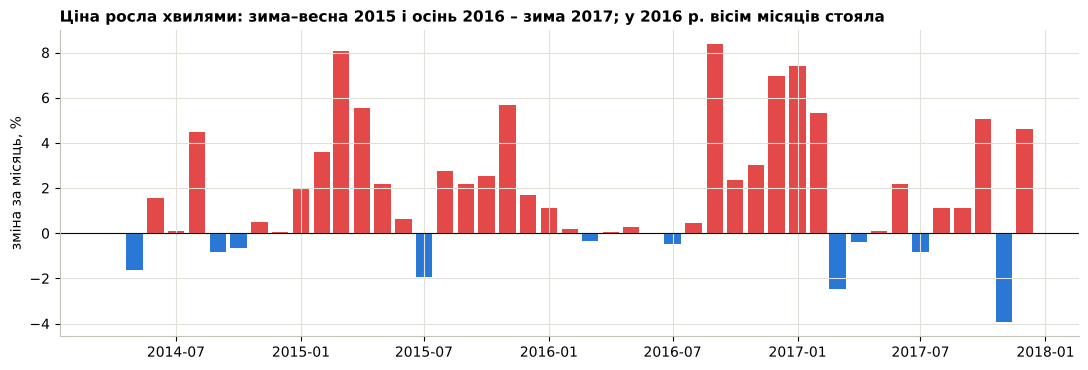

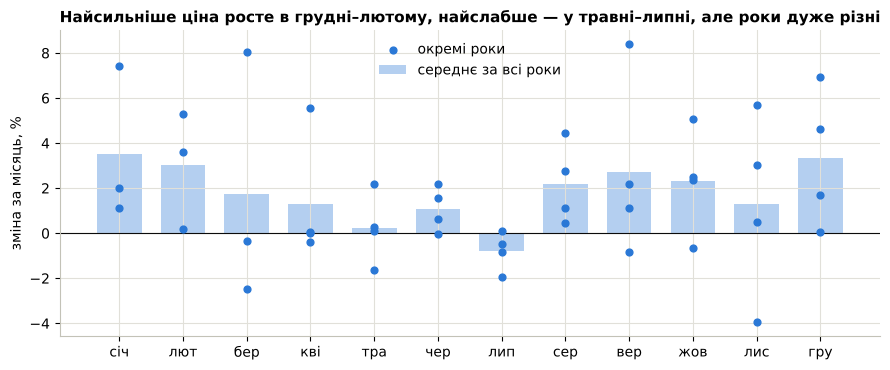

Загальне подорожчання: 9.13 грн/л (вересень–лютий дали 7.29, березень–серпень — 1.84)
01–08.2016 ціна в межах 11.48–11.54 грн/л, а у 09.2016 за один місяць +8.4 %
Середня зміна за календарний місяць, %:
місяць
січ    3.52
лют    3.02
бер    1.75
кві    1.30
тра    0.23
чер    1.09
лип   -0.79
сер    2.20
вер    2.71
жов    2.32
лис    1.32
гру    3.32


In [6]:
# Завдання 3. Візуальна розвідка
chg = y.pct_change().mul(100).dropna()            # зміна ціни за місяць, %
d_uah = y.diff().dropna()                         # зміна ціни за місяць, грн

# Графік 1. Питання: як змінювалась ціна за 4 роки — рівномірно чи стрибками?
fig, ax = plt.subplots()
ax.plot(y.index, y, color=BLUE, lw=2, marker='o', ms=3.5, label='ціна, щомісяця')
ax.plot(g, y[g], 'o', ms=10, mfc='white', mec=ORANGE, mew=2, label='08.2017 — заповнено інтерполяцією')
ax.set_ylabel(f'ціна, {UNIT}')
ax.set_title(f'Ціна зросла з {y.iloc[0]:.2f} до {y.iloc[-1]:.2f} {UNIT} (у {y.iloc[-1]/y.iloc[0]:.1f} раза) — сходинками, а не рівно')
ax.legend(loc='upper left', frameon=False)
show(fig, 't3_1_line')

# Графік 2. Питання: у які саме місяці ціна росла і на скільки?
fig, ax = plt.subplots()
ax.bar(chg.index, chg, width=24, color=np.where(chg >= 0, RED, BLUE))
ax.axhline(0, color=INK, lw=0.8)
ax.set_ylabel('зміна за місяць, %')
ax.set_title('Ціна росла хвилями: зима–весна 2015 і осінь 2016 – зима 2017; у 2016 р. вісім місяців стояла')
show(fig, 't3_2_changes')

# Графік 3. Питання: чи повторюється ріст щороку в ті самі місяці (сезонність)?
prof = pd.DataFrame({'місяць': chg.index.month, 'рік': chg.index.year, 'зміна': chg.values})
mean_by_month = prof.groupby('місяць')['зміна'].mean()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(mean_by_month.index, mean_by_month, width=0.7, color=BLUE, alpha=0.35, label='середнє за всі роки')
ax.scatter(prof['місяць'], prof['зміна'], s=24, color=BLUE, zorder=3, label='окремі роки')
ax.axhline(0, color=INK, lw=0.8)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTHS_UA)
ax.set_ylabel('зміна за місяць, %')
ax.set_title('Найсильніше ціна росте в грудні–лютому, найслабше — у травні–липні, але роки дуже різні')
ax.legend(frameon=False, loc='upper center')
show(fig, 't3_3_profile')

# Числа до висновків
plateau = y['2016-01-01':'2016-08-01']
cold = d_uah[d_uah.index.month.isin([9, 10, 11, 12, 1, 2])].sum()
warm = d_uah[d_uah.index.month.isin([3, 4, 5, 6, 7, 8])].sum()
print(f'Загальне подорожчання: {y.iloc[-1] - y.iloc[0]:.2f} {UNIT} '
      f'(вересень–лютий дали {cold:.2f}, березень–серпень — {warm:.2f})')
print(f'01–08.2016 ціна в межах {plateau.min():.2f}–{plateau.max():.2f} {UNIT}, '
      f'а у 09.2016 за один місяць +{chg["2016-09-01"]:.1f} %')
print('Середня зміна за календарний місяць, %:')
print(mean_by_month.round(2).rename(index=dict(enumerate(MONTHS_UA, 1))).to_string())

**Висновок до завдання 3:**

**Графік 1 — лінія в часі.** Питання: як змінювалась ціна? Лінія, бо точки впорядковані в часі й сусідні місяці пов'язані; шкала лінійна (грн/л), вісь не з нуля — для лінії важливий нахил, а не довжина. Ціна зросла з 7.83 до 16.96 грн/л (у 2.2 раза), але **сходинками**.

**Графік 2 — стовпці зміни за місяць, %.** Питання: коли саме ціна росла? Стовпці, бо кожне значення — окрема зміна відносно нуля, тому вісь обов'язково від нуля; відсотки, а не гривні, бо ціна подвоїлась і +0.3 грн у 2014 та 2017 — різні речі; колір — знак (червоний — дорожчання, синій — здешевлення). Видно дві хвилі: зима–весна 2015 і осінь 2016 – зима 2017.

**Графік 3 — сезонний профіль.** Питання: чи повторюється ріст щороку в ті самі місяці? По осі X — місяць року, а не час; крапки — окремі роки, стовпчик — середнє, щоб бачити і закономірність, і розкид. Найбільше ціна росте в грудні–лютому (+3.0…+3.5 % за місяць), найменше — у травні–липні (від −0.8 до +1.1 %), але між роками розкид великий.

**Неочікувана знахідка:** з січня по серпень 2016 р. ціна **вісім місяців стояла** (11.48–11.54 грн/л), а у вересні 2016 за один місяць зросла на **8.4 %**. Загалом 7.29 грн із 9.13 грн усього подорожчання (80 %) припали на вересень–лютий.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

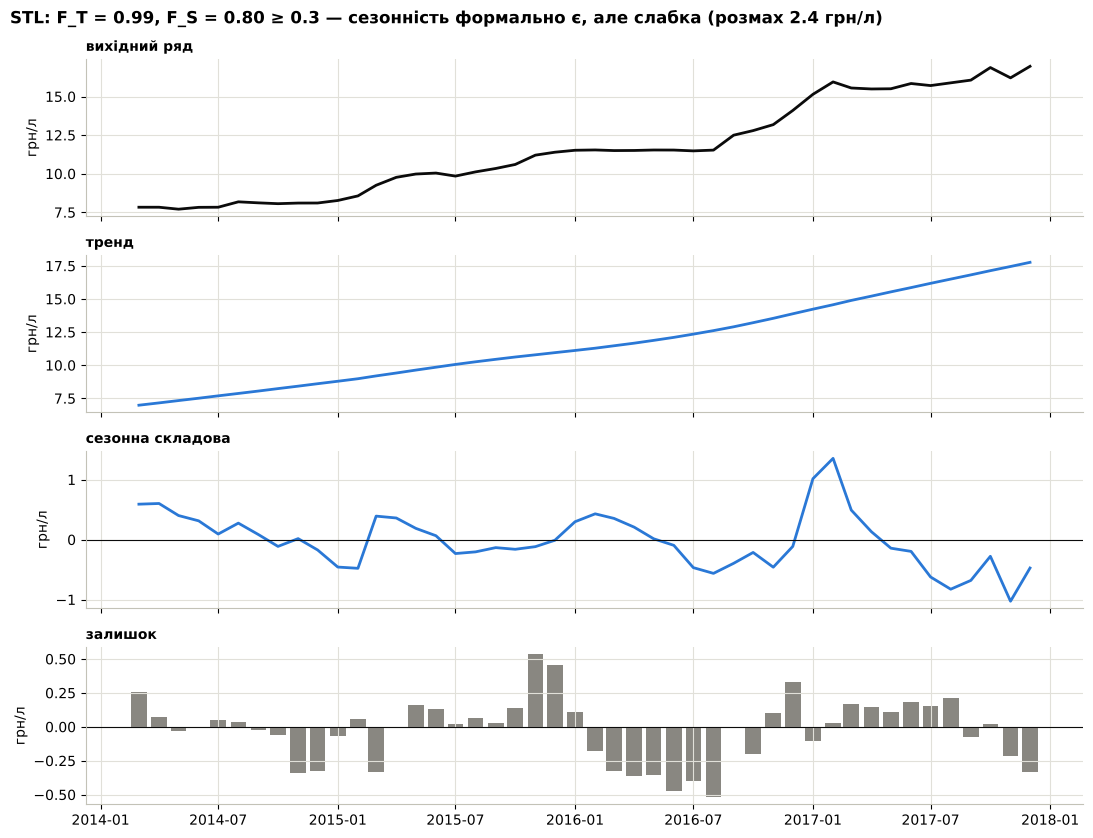

Сила тренду      F_T = 0.994
Сила сезонності  F_S = 0.805   (поріг 0.3)
Розмах сезонної складової: 2.382 грн/л; розмах тренду: 10.78 грн/л
Висновок за порогом: сезонність Є
Середня сезонна складова за місяцями, грн/л: січ +0.29, лют +0.44, бер +0.46, кві +0.33, тра +0.12, чер +0.02, лип -0.31, сер -0.33, вер -0.28, жов -0.19, лис -0.40, гру -0.19
Контроль: на 200 рядах чистого шуму з 46 точок F_S = 0.62 (медіана), у 10 % випадків > 0.74 — на короткому ряді поріг 0.3 перевищує навіть шум


In [7]:
# Завдання 4. Розкладання на складові (STL, період 12)
stl = STL(y, period=12).fit()
T, S, R = stl.trend, stl.seasonal, stl.resid

# Сила тренду та сезонності: яку частку «шуму» пояснює складова
F_T = max(0.0, 1 - R.var() / (T + R).var())
F_S = max(0.0, 1 - R.var() / (S + R).var())

fig, axes = plt.subplots(4, 1, figsize=(11, 8.5), sharex=True)
parts = [(y, 'вихідний ряд', INK), (T, 'тренд', BLUE), (S, 'сезонна складова', BLUE), (R, 'залишок', GRAY)]
for ax, (comp, title, color) in zip(axes, parts):
    if title == 'залишок':
        ax.bar(comp.index, comp, width=24, color=color)
        ax.axhline(0, color=INK, lw=0.8)
    else:
        ax.plot(comp.index, comp, color=color, lw=2)
    ax.set_ylabel(UNIT)
    ax.set_title(title, fontsize=10)
axes[2].axhline(0, color=INK, lw=0.8)
fig.suptitle(f'STL: F_T = {F_T:.2f}, F_S = {F_S:.2f} ≥ 0.3 — сезонність формально є, '
             f'але слабка (розмах {S.max() - S.min():.1f} {UNIT})', x=0.01, ha='left', fontweight='bold')
show(fig, 't4_stl')

print(f'Сила тренду      F_T = {F_T:.3f}')
print(f'Сила сезонності  F_S = {F_S:.3f}   (поріг 0.3)')
print(f'Розмах сезонної складової: {S.max() - S.min():.3f} {UNIT}; розмах тренду: {T.max() - T.min():.2f} {UNIT}')
print('Висновок за порогом:', 'сезонність Є' if F_S >= 0.3 else 'сезонності фактично НЕМАЄ')
by_month = S.groupby(S.index.month).mean()
print('Середня сезонна складова за місяцями, ' + UNIT + ':',
      ', '.join(f'{MONTHS_UA[m - 1]} {val:+.2f}' for m, val in by_month.items()))

# Контроль: який F_S дає STL на чистому шумі тієї ж довжини (сезонності там немає за побудовою)
rng = np.random.default_rng(0)
fs_noise = []
for _ in range(200):
    r = STL(rng.normal(size=len(y)), period=12).fit()
    fs_noise.append(max(0.0, 1 - np.var(r.resid) / np.var(r.seasonal + r.resid)))
print(f'Контроль: на 200 рядах чистого шуму з {len(y)} точок F_S = {np.median(fs_noise):.2f} (медіана), '
      f'у 10 % випадків > {np.percentile(fs_noise, 90):.2f} — на короткому ряді поріг 0.3 перевищує навіть шум')

**Висновок до завдання 4:**

Сила тренду **F_T = 0.994**, сила сезонності **F_S = 0.805**.

**Висновок за порогом: сезонність є** (F_S = 0.805 > 0.3). Форма: ціна вища за тренд у січні–квітні (до +0.46 грн/л) і нижча в липні–листопаді (до −0.40 грн/л). Це збігається з графіком 3 і з логікою ринку молока: влітку молока більше, тож воно відносно дешевше.

Але сезонність **слабка**: її розмах 2.4 грн/л проти 10.8 грн/л тренду, майже всю мінливість пояснює тренд. Застереження: на ряді з 46 точок STL дає F_S ≈ 0.62 навіть **для чистого шуму** (контроль у коді), тобто поріг 0.3 тут перевищується майже завжди. Тож упевнено можна сказати лише одне: ціна росте здебільшого восени–взимку; точну форму сезонності за 4 роки даних не встановити.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

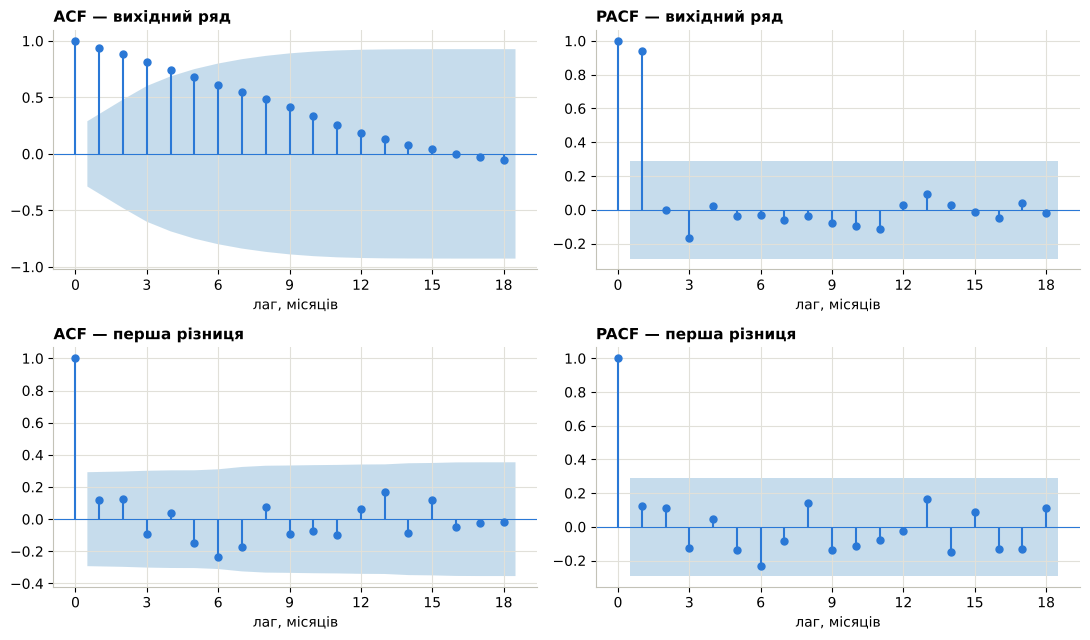

вихідний ряд   значущі лаги ACF: [1, 2, 3, 4] | PACF: [1]
перша різниця  значущі лаги ACF: [] | PACF: []

          ряд   ADF p   висновок ADF  KPSS p  висновок KPSS узгоджуються?
 вихідний ряд   0.988 нестаціонарний ≤ 0.010 нестаціонарний           так
перша різниця < 0.001   стаціонарний ≥ 0.100   стаціонарний           так


In [8]:
# Завдання 5. Стаціонарність
dy = y.diff().dropna()        # перша різниця: на скільки гривень змінилась ціна за місяць
LAGS = 18                     # видно сезонний лаг 12 і трохи далі; більше 18 для 45–46 точок не варто

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
plot_acf(y, lags=LAGS, ax=axes[0, 0], color=BLUE, vlines_kwargs={'colors': BLUE}, title='ACF — вихідний ряд')
plot_pacf(y, lags=LAGS, ax=axes[0, 1], method='ywm', color=BLUE, vlines_kwargs={'colors': BLUE}, title='PACF — вихідний ряд')
plot_acf(dy, lags=LAGS, ax=axes[1, 0], color=BLUE, vlines_kwargs={'colors': BLUE}, title='ACF — перша різниця')
plot_pacf(dy, lags=LAGS, ax=axes[1, 1], method='ywm', color=BLUE, vlines_kwargs={'colors': BLUE}, title='PACF — перша різниця')
for ax in axes.flat:
    ax.set_xlabel('лаг, місяців')
    ax.set_xticks(range(0, LAGS + 1, 3))
show(fig, 't5_acf_pacf')

def significant_lags(x, kind):
    """Лаги, де стовпчик виходить за 95 % смугу (як на графіку)."""
    if kind == 'acf':
        vals, ci = acf(x, nlags=LAGS, alpha=0.05)
    else:
        vals, ci = pacf(x, nlags=LAGS, alpha=0.05, method='ywm')
    half = (ci[:, 1] - ci[:, 0]) / 2              # півширина смуги довкола нуля
    return [k for k in range(1, LAGS + 1) if abs(vals[k]) > half[k]]

for name, x in [('вихідний ряд', y), ('перша різниця', dy)]:
    print(f'{name:14s} значущі лаги ACF: {significant_lags(x, "acf")} | PACF: {significant_lags(x, "pacf")}')

# Тести: ADF (H0: ряд НЕстаціонарний) і KPSS (H0: ряд стаціонарний) — гіпотези протилежні
def fmt_kpss(p):
    return '≤ 0.010' if p <= 0.01 else ('≥ 0.100' if p >= 0.1 else f'{p:.3f}')

rows = []
for name, x in [('вихідний ряд', y), ('перша різниця', dy)]:
    p_adf = adfuller(x, autolag='AIC')[1]
    p_kpss = kpss(x, regression='c', nlags='auto')[1]
    adf_says = 'стаціонарний' if p_adf < 0.05 else 'нестаціонарний'
    kpss_says = 'нестаціонарний' if p_kpss < 0.05 else 'стаціонарний'
    rows.append([name, '< 0.001' if p_adf < 0.001 else f'{p_adf:.3f}', adf_says, fmt_kpss(p_kpss), kpss_says,
                 'так' if adf_says == kpss_says else 'НІ'])
tests = pd.DataFrame(rows, columns=['ряд', 'ADF p', 'висновок ADF', 'KPSS p', 'висновок KPSS', 'узгоджуються?'])
print()
print(tests.to_string(index=False))

**Висновок до завдання 5:**

Вихідний ряд: ACF спадає повільно (значущі лаги 1–4), у PACF один сильний лаг 1 — типовий вигляд ряду з трендом. Перша різниця: **жодного значущого лагу** ні в ACF, ні в PACF.

| ряд | ADF p | висновок ADF | KPSS p | висновок KPSS | узгоджуються? |
|---|---|---|---|---|---|
| вихідний | 0.988 | нестаціонарний | ≤ 0.010 | нестаціонарний | так |
| перша різниця | < 0.001 | стаціонарний | ≥ 0.100 | стаціонарний | так |

Напрямок гіпотез: в **ADF** H₀ — «ряд нестаціонарний» (мале p → стаціонарний), у **KPSS** навпаки H₀ — «ряд стаціонарний» (мале p → нестаціонарний). Для вихідного ряду ADF не відкидає нестаціонарність, а KPSS відкидає стаціонарність — обидва кажуть «**нестаціонарний**». Для першої різниці — обидва кажуть «**стаціонарна**». Тести **узгоджуються**, отже d = 1. (KPSS у statsmodels дає p лише в межах 0.01–0.10, тому значення на межах подано як «≤» і «≥».)

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

фолд 1: навчання 03.2014–03.2016 (25 міс.) → прогноз 04.2016–06.2016
фолд 2: навчання 03.2014–06.2016 (28 міс.) → прогноз 07.2016–09.2016
фолд 3: навчання 03.2014–09.2016 (31 міс.) → прогноз 10.2016–12.2016
фолд 4: навчання 03.2014–12.2016 (34 міс.) → прогноз 01.2017–03.2017
фолд 5: навчання 03.2014–03.2017 (37 міс.) → прогноз 04.2017–06.2017
фолд 6: навчання 03.2014–06.2017 (40 міс.) → прогноз 07.2017–09.2017
фолд 7: навчання 03.2014–09.2017 (43 міс.) → прогноз 10.2017–12.2017

Рухомий початок, 7 фолдів × 3 кроки:
                    MAE   RMSE  MAPE, %
наївний           0.509  0.766    3.412
сезонний наївний  3.016  3.206   20.429
середнє           4.125  4.349   27.924
дрейф             0.481  0.585    3.302
Найкращий базис: дрейф


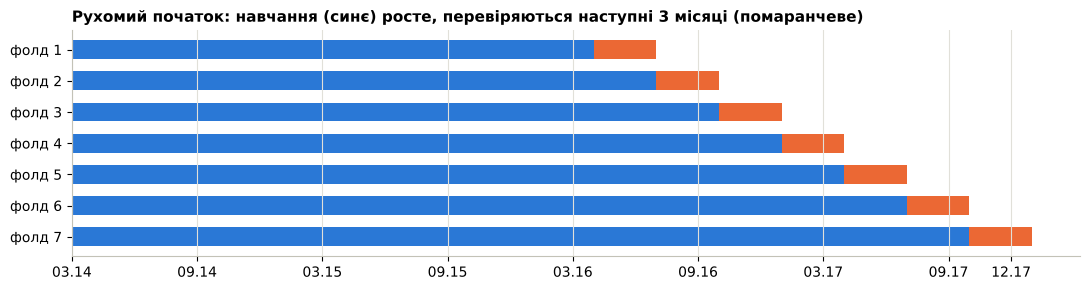


Випадковий поділ: тестові місяці 06.14, 07.14, 09.14, 11.14, 03.15, 03.16, 04.16, 05.16, 02.17, 06.17, 08.17, 11.17

Рухомий початок проти випадкового поділу 75/25:
                  MAE рухомий  MAE випадковий  у скільки разів  RMSE рухомий  RMSE випадковий
наївний                 0.509           0.249            2.044         0.766            0.380
сезонний наївний        3.016           2.884            1.046         3.206            3.136
середнє                 4.125           2.894            1.425         4.349            3.353
дрейф                   0.481           0.302            1.593         0.585            0.378


In [9]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка (рухомий початок)
v = y.values
n = len(v)

# 7 фолдів, відлічуємо від кінця ряду: навчання — усе до позиції n−3f, тест — наступні 3 місяці
FOLDS = [(n - H * f, n - H * f + H) for f in range(N_FOLDS, 0, -1)]
for i, (a, b) in enumerate(FOLDS, 1):
    print(f'фолд {i}: навчання {grid[0]:%m.%Y}–{grid[a-1]:%m.%Y} ({a} міс.) → прогноз {grid[a]:%m.%Y}–{grid[b-1]:%m.%Y}')
test_y = np.concatenate([v[a:b] for a, b in FOLDS])          # 21 перевірений місяць

# Чотири базиси: train — відомі значення, h — на скільки місяців уперед
def naive(train, h):  return np.repeat(train[-1], h)                       # «буде як зараз»
def snaive(train, h): return train[-12:][:h]                              # «як рік тому в цей місяць»
def mean_f(train, h): return np.repeat(train.mean(), h)                   # «як у середньому за всю історію»
def drift(train, h):  return train[-1] + (train[-1] - train[0]) / (len(train) - 1) * np.arange(1, h + 1)  # «ріст триває»

def rolling_origin(forecast_fn):
    """Прогнози на всіх 7 фолдах, склеєні в хронологічному порядку (21 значення)."""
    return np.concatenate([forecast_fn(v[:a], b - a) for a, b in FOLDS])

def metrics(true, pred):
    e = true - pred
    return {'MAE': np.mean(np.abs(e)), 'RMSE': np.sqrt(np.mean(e ** 2)), 'MAPE, %': np.mean(np.abs(e / true)) * 100}

BASELINES = {'наївний': naive, 'сезонний наївний': snaive, 'середнє': mean_f, 'дрейф': drift}
base_pred = {name: rolling_origin(fn) for name, fn in BASELINES.items()}
base_tab = pd.DataFrame({name: metrics(test_y, p) for name, p in base_pred.items()}).T
best = base_tab['MAE'].idxmin()
print('\nРухомий початок, 7 фолдів × 3 кроки:')
print(base_tab.round(3).to_string())
print('Найкращий базис:', best)

# Схема фолдів (для розуміння): синє — навчання, помаранчеве — перевірка
fig, ax = plt.subplots(figsize=(11, 3))
for i, (a, b) in enumerate(FOLDS):
    ax.barh(i, a, left=0, color=BLUE, height=0.6)
    ax.barh(i, b - a, left=a, color=ORANGE, height=0.6)
ax.set_yticks(range(N_FOLDS)); ax.set_yticklabels([f'фолд {i}' for i in range(1, N_FOLDS + 1)])
ticks = list(range(0, n, 6)) + [n - 1]
ax.set_xticks(ticks); ax.set_xticklabels([grid[t].strftime('%m.%y') for t in ticks])
ax.invert_yaxis(); ax.grid(axis='y', visible=False)
ax.set_title('Рухомий початок: навчання (синє) росте, перевіряються наступні 3 місяці (помаранчеве)')
show(fig, 't6_folds')

# Для порівняння: «звичайний» випадковий поділ 75/25 (як для таблиць без часу).
# Кожен місяць — рядок таблиці; ознака — попереднє значення; рядки перемішуються.
tr_idx, te_idx = train_test_split(np.arange(n), test_size=0.25, random_state=42)
te_idx = np.sort(te_idx)
print('\nВипадковий поділ: тестові місяці', ', '.join(grid[t].strftime('%m.%y') for t in te_idx))
step_tr = np.mean([v[t] - v[t - 1] for t in tr_idx if t >= 1])   # середній крок за навчальними місяцями (є й пізніші!)
rand_rule = {
    'наївний':          lambda t: v[t - 1] if t >= 1 else np.nan,
    'сезонний наївний': lambda t: v[t - 12] if t >= 12 else np.nan,
    'середнє':          lambda t: v[tr_idx].mean(),
    'дрейф':            lambda t: v[t - 1] + step_tr if t >= 1 else np.nan,
}
rand_tab = {}
for name, rule in rand_rule.items():
    p = np.array([rule(t) for t in te_idx])
    ok = ~np.isnan(p)
    rand_tab[name] = metrics(v[te_idx][ok], p[ok])
rand_tab = pd.DataFrame(rand_tab).T

compare = pd.DataFrame({
    'MAE рухомий': base_tab['MAE'], 'MAE випадковий': rand_tab['MAE'],
    'у скільки разів': base_tab['MAE'] / rand_tab['MAE'],
    'RMSE рухомий': base_tab['RMSE'], 'RMSE випадковий': rand_tab['RMSE'],
})
print('\nРухомий початок проти випадкового поділу 75/25:')
print(compare.round(3).to_string())

**Висновок до завдання 6:**

| базис | MAE | RMSE | MAPE, % |
|---|---|---|---|
| наївний | 0.509 | 0.766 | 3.41 |
| сезонний наївний | 3.016 | 3.206 | 20.43 |
| середнє | 4.125 | 4.349 | 27.92 |
| **дрейф** | **0.481** | **0.585** | **3.30** |

**Найкращий — дрейф**, наївний поруч. Причина у властивостях ряду: сильний тренд (F_T = 0.99), а місячні зміни без «пам'яті» (у різниці немає значущих лагів), тому найкраща оцінка — остання ціна плюс середній темп зростання. Сезонний наївний провалюється, бо повторює ціну рік тому й ігнорує цілий рік подорожчання; середнє — найгірше, бо тягне в прогноз дешеві ціни 2014 р.

**Випадковий поділ 75/25** дає похибку в **1.6 раза** меншу для дрейфу (0.302 проти 0.481) і **у 2 рази** меншу для наївного (0.249 проти 0.509) і навіть міняє переможця. Причина — витік майбутнього: після перемішування кожен тестовий місяць прогнозується на 1 крок від справжнього сусіда, а середнє й дрейф рахуються по навчальних місяцях, серед яких є й пізніші. Така оцінка надто оптимістична.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

ARIMA(1,1,1), рухомий початок: MAE = 0.344, RMSE = 0.455, MAPE, % = 2.308

                                          MAE   RMSE  MAPE, %
ARIMA(1, 1, 1)                          0.344  0.455    2.308
ARIMA(0, 1, 0) (мій вибір за ACF/PACF)  0.509  0.766    3.412
дрейф (найкращий базис)                 0.481  0.585    3.302
наївний                                 0.509  0.766    3.412

MAE ARIMA(1, 1, 1) / MAE дрейф = 0.71 → ARIMA точніша на 29 %
ARIMA(0, 1, 0) дає ті самі прогнози, що й наївний метод: True

Параметри ARIMA(1,1,1) у фолдах:
       фолд 1  фолд 2  фолд 3  фолд 4  фолд 5  фолд 6  фолд 7
ar.L1    0.64    0.65    0.61    0.83    0.53    0.58    0.61
ma.L1   -0.09   -0.09   -0.02   -0.35    0.10    0.01   -0.07
Для порівняння: ACF лагу 1 першої різниці на всьому ряді = 0.12 (межа значущості ±0.29)


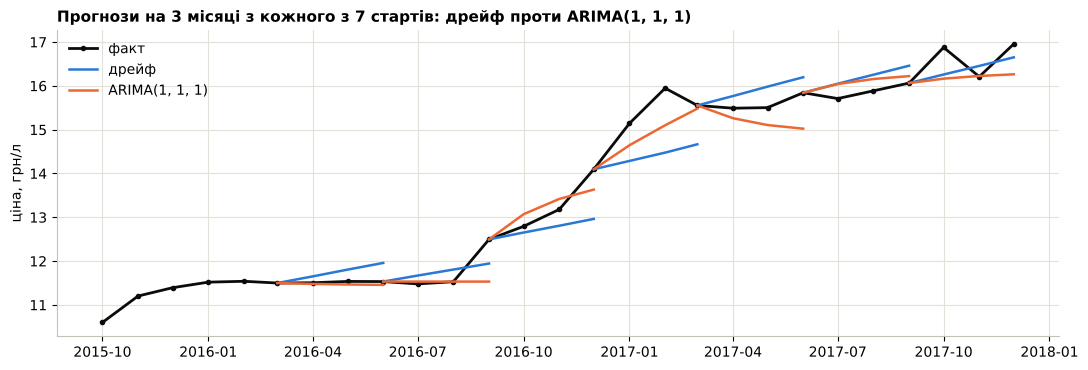


Тест Льюнга–Бокса для залишків (H0: залишки — білий шум):
    lb_stat  lb_pvalue
6     7.171      0.127
12   11.618      0.311


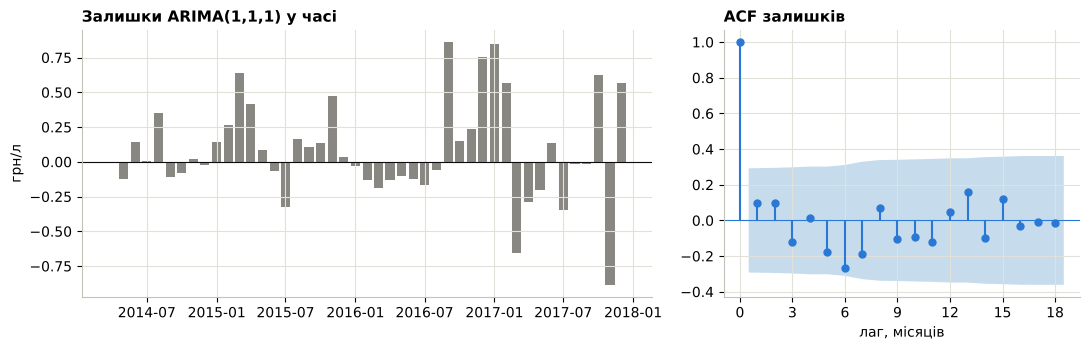

Значущі лаги ACF залишків: []


In [10]:
# Завдання 7. Модель ARIMA на тих самих фолдах
def arima_fc(train, h, order=ORDER):
    return ARIMA(train, order=order).fit().forecast(h)

arima_pred = rolling_origin(arima_fc)                    # 21 прогноз ARIMA(1,1,1)
arima_m = metrics(test_y, arima_pred)
print('ARIMA(1,1,1), рухомий початок:', ', '.join(f'{k} = {val:.3f}' for k, val in arima_m.items()))

# Власний вибір порядку за ACF/PACF (завдання 5): d = 1 (після однієї різниці ряд стаціонарний),
# p = 0 (у PACF різниці немає значущих лагів), q = 0 (в ACF різниці теж немає) → ARIMA(0,1,0)
MY_ORDER = (0, 1, 0)
my_pred = rolling_origin(lambda tr, h: arima_fc(tr, h, MY_ORDER))

cmp = pd.DataFrame({
    f'ARIMA{ORDER}': arima_m,
    f'ARIMA{MY_ORDER} (мій вибір за ACF/PACF)': metrics(test_y, my_pred),
    f'{best} (найкращий базис)': base_tab.loc[best].to_dict(),
    'наївний': base_tab.loc['наївний'].to_dict(),
}).T
print()
print(cmp.round(3).to_string())
ratio = arima_m['MAE'] / base_tab.loc[best, 'MAE']
print(f'\nMAE ARIMA{ORDER} / MAE {best} = {ratio:.2f} → ARIMA точніша на {(1 - ratio) * 100:.0f} %')
print(f'ARIMA{MY_ORDER} дає ті самі прогнози, що й наївний метод:', np.allclose(my_pred, base_pred['наївний']))

# Параметри тих моделей, що дали прогнози (одна модель на фолд): φ = ar.L1, θ = ma.L1
fold_fits = [ARIMA(v[:a], order=ORDER).fit() for a, _ in FOLDS]
fold_par = pd.DataFrame([dict(zip(r.param_names, r.params)) for r in fold_fits],
                        index=[f'фолд {i}' for i in range(1, N_FOLDS + 1)])[['ar.L1', 'ma.L1']]
print('\nПараметри ARIMA(1,1,1) у фолдах:')
print(fold_par.round(2).T.to_string())
print(f'Для порівняння: ACF лагу 1 першої різниці на всьому ряді = {acf(dy, nlags=1)[1]:.2f} '
      f'(межа значущості ±{1.96 / np.sqrt(len(dy)):.2f})')

# Прогнози на фолдах поруч із фактом
fig, ax = plt.subplots()
k0 = FOLDS[0][0] - 6
ax.plot(grid[k0:], v[k0:], color=INK, lw=2, marker='o', ms=3, label='факт')
for i, (a, b) in enumerate(FOLDS):
    idx = grid[a - 1:b]                                   # від останньої відомої точки
    ax.plot(idx, np.r_[v[a - 1], base_pred[best][3 * i:3 * i + 3]], color=BLUE, lw=1.8,
            label=f'{best}' if i == 0 else None)
    ax.plot(idx, np.r_[v[a - 1], arima_pred[3 * i:3 * i + 3]], color=ORANGE, lw=1.8,
            label=f'ARIMA{ORDER}' if i == 0 else None)
ax.set_ylabel(f'ціна, {UNIT}')
ax.set_title(f'Прогнози на 3 місяці з кожного з 7 стартів: {best} проти ARIMA{ORDER}')
ax.legend(frameon=False, loc='upper left')
show(fig, 't7_forecasts')

# Залишки моделі, навченої на всьому ряді (перший залишок технічний — відкидаємо)
fit_full = ARIMA(y.values, order=ORDER).fit()
resid = pd.Series(fit_full.resid[1:], index=grid[1:])
lb = acorr_ljungbox(resid, lags=[6, 12], model_df=2)
print('\nТест Льюнга–Бокса для залишків (H0: залишки — білий шум):')
print(lb.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={'width_ratios': [1.6, 1]})
axes[0].bar(resid.index, resid, width=24, color=GRAY)
axes[0].axhline(0, color=INK, lw=0.8)
axes[0].set_ylabel(UNIT)
axes[0].set_title('Залишки ARIMA(1,1,1) у часі')
plot_acf(resid, lags=LAGS, ax=axes[1], color=BLUE, vlines_kwargs={'colors': BLUE}, title='ACF залишків')
axes[1].set_xlabel('лаг, місяців')
axes[1].set_xticks(range(0, LAGS + 1, 3))
show(fig, 't7_residuals')
print('Значущі лаги ACF залишків:', significant_lags(resid, 'acf'))

**Висновок до завдання 7:**

**ARIMA(1,1,1)** на тих самих 7 фолдах: **MAE 0.344 грн/л, RMSE 0.455, MAPE 2.31 %**.

**Мій порядок за ACF/PACF — ARIMA(0,1,0):** d = 1, бо за ADF/KPSS однієї різниці досить; p = 0, бо в PACF різниці немає значущих лагів; q = 0, бо в ACF різниці їх теж немає. Така модель — «випадкове блукання», її прогноз збігається з наївним (MAE 0.509, перевірено в коді).

**Порівняння з найкращим базисом:** ARIMA(1,1,1) точніша за дрейф на 29 % (0.344 проти 0.481) і за наївний на 32 % → **модель має право на існування**. Чому, хоча ACF різниці «нічого не бачить»: у фолдах φ = 0.53–0.83 — модель вловила, що зміни ціни йдуть **хвилями** (після росту частіше ріст, після плато — плато). Тому на плато 2016 р. вона прогнозує плато, а після стрибка — ріст, що поступово згасає; дрейф же всюди додає середній темп за всю історію. На всьому ряді ця інерція слабка (ACF лагу 1 різниці — лише 0.12, у межах смуги), тому стовпчики ACF її не показують.

**Залишки:** тест Льюнга–Бокса дає p > 0.1 і для 6, і для 12 лагів, значущих лагів в ACF залишків немає → **структури не лишилось**, залишки схожі на білий шум.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

Кандидатних дат: 35
Знайдена точка: новий рівень з 01.2017 | t = 16.60
Середнє до (03.2014–12.2016): 10.11 грн/л; після (01.2017–12.2017): 15.93 грн/л; зсув +5.82
«Наївне» p t-тесту: 2.0e-20 — не можна вірити (вибір максимуму + залежні спостереження)
Перестановковий тест (5000 перемішувань): p = 0.074; 95-й процентиль «випадкового» t = 17.0
Висновок: точка НЕ значуща на рівні 0.05
Зсув рівня 5.82 грн/л проти розмаху сезонної складової 2.38 грн/л
Рівні не перетинаються: після 01.2017 мінімум 15.14, а до того максимум 14.10 грн/л — ціна не повернулась на старий рівень


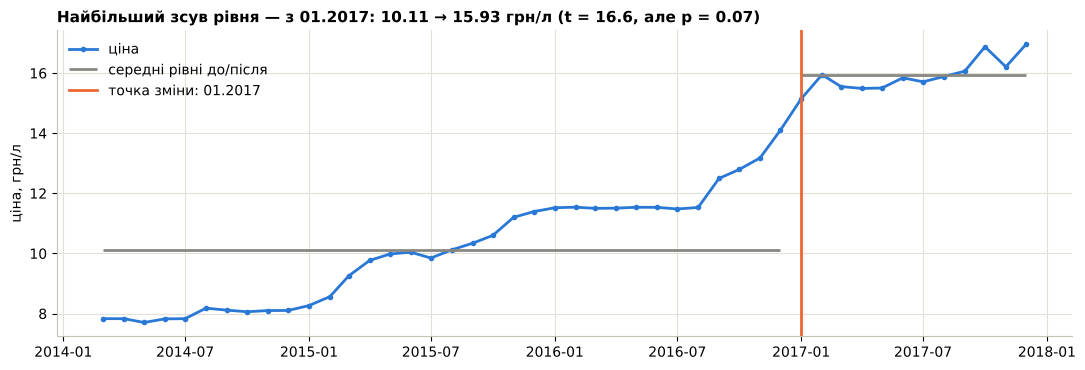

In [11]:
# Завдання 8. Точка зміни режиму (зсув рівня)
MIN_SEG = 6                                   # у кожному відрізку щонайменше пів року

def scan(x, m=MIN_SEG):
    """t-статистика Велча «середнє після − середнє до» для кожної кандидатної дати."""
    res = []
    for k in range(m, len(x) - m + 1):
        a, b = x[:k], x[k:]
        t = (b.mean() - a.mean()) / np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
        res.append((k, t))
    return res

cands = scan(v)
k_best, t_best = max(cands, key=lambda z: abs(z[1]))
cp = grid[k_best]
m_before, m_after = v[:k_best].mean(), v[k_best:].mean()
print(f'Кандидатних дат: {len(cands)}')
print(f'Знайдена точка: новий рівень з {cp:%m.%Y} | t = {t_best:.2f}')
print(f'Середнє до (03.2014–{grid[k_best-1]:%m.%Y}): {m_before:.2f} {UNIT}; '
      f'після ({cp:%m.%Y}–12.2017): {m_after:.2f} {UNIT}; зсув {m_after - m_before:+.2f}')

# Звичайне p-значення t-тесту тут нечесне: ми вибрали найкращу з 35 дат, а сусідні місяці залежні
p_naive = stats.ttest_ind(v[k_best:], v[:k_best], equal_var=False).pvalue
print(f'«Наївне» p t-тесту: {p_naive:.1e} — не можна вірити (вибір максимуму + залежні спостереження)')

# Чесна перевірка: перемішуємо місячні зміни ціни. Загальне подорожчання те саме,
# але особливої дати вже немає. Наскільки часто такий ряд дає t не менший за наш?
rng = np.random.default_rng(42)
B = 5000
steps = np.diff(v)
null_t = np.array([max(abs(t) for _, t in scan(np.r_[v[0], v[0] + np.cumsum(rng.permutation(steps))]))
                   for _ in range(B)])
p_perm = (np.sum(null_t >= abs(t_best)) + 1) / (B + 1)
print(f'Перестановковий тест ({B} перемішувань): p = {p_perm:.3f}; '
      f'95-й процентиль «випадкового» t = {np.percentile(null_t, 95):.1f}')
print('Висновок:', 'точка ЗНАЧУЩА' if p_perm < 0.05 else 'точка НЕ значуща на рівні 0.05')

# Порівняння з сезонністю: зсув рівня проти розмаху сезонної складової STL
print(f'Зсув рівня {m_after - m_before:.2f} {UNIT} проти розмаху сезонної складової {S.max() - S.min():.2f} {UNIT}')
print(f'Рівні не перетинаються: після {cp:%m.%Y} мінімум {v[k_best:].min():.2f}, '
      f'а до того максимум {v[:k_best].max():.2f} {UNIT} — ціна не повернулась на старий рівень')

fig, ax = plt.subplots()
ax.plot(grid, v, color=BLUE, lw=2, marker='o', ms=3, label='ціна')
ax.hlines(m_before, grid[0], grid[k_best - 1], color=GRAY, lw=2, label='середні рівні до/після')
ax.hlines(m_after, grid[k_best], grid[-1], color=GRAY, lw=2)
ax.axvline(cp, color=ORANGE, lw=2, label=f'точка зміни: {cp:%m.%Y}')
ax.set_ylabel(f'ціна, {UNIT}')
ax.set_title(f'Найбільший зсув рівня — з {cp:%m.%Y}: {m_before:.2f} → {m_after:.2f} {UNIT} (t = {t_best:.1f}, але p = {p_perm:.2f})')
ax.legend(frameon=False, loc='upper left')
show(fig, 't8_changepoint')

**Висновок до завдання 8:**

Найбільша t-статистика — новий рівень **з 01.2017**, **t = 16.6**. Середнє до (03.2014–12.2016) — **10.11 грн/л**, після (01–12.2017) — **15.93 грн/л**, зсув **+5.82 грн/л**.

**Значущість:** звичайний t-тест дав би p ≈ 2·10⁻²⁰, але він тут нечесний — ми самі вибрали найкращу з 35 дат, а сусідні місяці залежні. Чесна перевірка: 5000 разів перемішуємо місячні зміни ціни (загальне подорожчання те саме, особливої дати немає) — такі ряди дають t ≥ 16.6 у 7.4 % випадків, **p = 0.074 > 0.05**. Отже, **точка не значуща**: такий «стрибок» дає й звичайне зростання сходинками.

**Відмінність від сезонного сплеску:** після 01.2017 ціна не повертається — мінімум нового рівня 15.14 вищий за максимум старого 14.10, а зсув 5.82 грн більший за весь розмах сезонної складової (2.38 грн). Сезонний сплеск повторювався б щороку в ті самі місяці й зникав. У часі точка збігається з подвоєнням мінімальної зарплати з 1 січня 2017 р. (до 3200 грн), але це збіг у часі, а не доведена причина.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [12]:
# Завдання 9. Рецензія на чужий аналіз (ЛР4_помилковий_аналіз.ipynb, гречка, Вінниця)
# Номер клітинки = номер In [ ] у зошиті колеги.
review = pd.DataFrame([
    ['1–2', 'Сітку створено, але не застосовано; isna() на неперевпорядкованому ряді дає 0 → «пропусків немає»',
     'серпень 2017 просто відсутній: shift, diff, ACF, STL і ARIMA після нього зсунуті на місяць'],
    ['3', 'Висновок про «зниження купівельної спроможності» з двох крайніх точок номінальної ціни',
     'немає даних про доходи й інфляцію; крайні точки випадкові (у 07.2016 ціна була вдвічі вищою)'],
    ['4', 'Порівнює MAE у гривнях для товарів із різним рівнем ціни',
     'MAE залежить від масштабу: у відсотках яловичина прогнозується в 3 рази легше — висновок навпаки'],
    ['5', 'Кореляція двох рядів із трендом → «Львів визначає ціни у Вінниці»',
     'кореляція не показує причину й напрям; обидва ряди тягнуть спільні чинники (врожай, курс)'],
    ['6', 'Сезонність «доведено» тим, що STL виділив сезонну складову',
     'STL повертає сезонну складову завжди; без F_S і порогу висновок порожній'],
    ['7', 'ADF прочитано навпаки (p = 0.233 → «стаціонарний»), KPSS немає, ще й друга різниця «для надійності»',
     'хибний порядок d, зайве диференціювання підсилює шум і псує модель'],
    ['8', 'Аномалії — z-оцінка сирого ряду з трендом; у коді поріг 1.3, у тексті «2 стандартні відхилення»',
     '«аномаліями» стали 12 із 45 місяців — це фази тренду; з порогом 2 їх 0'],
    ['9', 'Випадковий поділ 75/25 для часового ряду, сортування навчальних і тестових значень',
     'модель «бачить майбутнє», порівнюються не ті місяці; MAE 8.73 названо «високою точністю», хоча це у 6 разів гірше за наївний (1.38)'],
    ['10', 'Прогноз іншою, неперевіреною моделлю ARIMA(2,2,1) без інтервалів; висновок «ціна зростатиме»',
     'надрукований прогноз 8.95 грн удвічі нижчий за останню ціну 17.67 — висновок суперечить числу'],
    ['11', 'Стовпчики з обрізаною віссю Y і вибраним вікном у пів року',
     'візуально роздуває зміни й приховує, що далі ціна впала вдвічі'],
    ['підсумок', 'Загальні висновки повторюють усі хибні твердження',
     'читач отримує «доведені» сезонність, стаціонарність, причинність і точність, яких немає'],
], columns=['клітинка', 'суть помилки', 'чим небезпечна'])
with pd.option_context('display.max_colwidth', None):
    print(review.to_string(index=False))

# Перевіряємо ключові твердження колеги числами на ТИХ САМИХ даних
def series(market, good):
    return (prices[(prices['ринок'] == market) & (prices['товар'] == good)]
            .set_index('date')['ціна'].sort_index())

buck = series('Vinnytsia', 'Buckwheat grits - Retail')
beef = series('Vinnytsia', 'Meat (beef) - Retail')
lviv = series('Lviv', 'Buckwheat grits - Retail')
print('\n[1–2] записів у ряді гречки:', len(buck), '| місяців у сітці:', len(grid),
      '| пропущено:', ', '.join(d.strftime('%m.%Y') for d in grid.difference(buck.index)))
for name, x in [('гречка', buck), ('яловичина', beef)]:
    e = (x - x.shift(1)).dropna()
    print(f'[4] {name:9s}: MAE наївного {e.abs().mean():.2f} грн, '
          f'але відносна похибка {(e.abs() / x.loc[e.index]).mean() * 100:.1f} % від ціни')
print(f'[5] кореляція рівнів {buck.corr(lviv):.3f}, кореляція місячних змін {buck.diff().corr(lviv.diff()):.3f} '
      '— сильний зв’язок, але не причина')
bg = buck.reindex(grid).interpolate()
st_b = STL(bg, period=12).fit()
F_S_b = max(0.0, 1 - st_b.resid.var() / (st_b.seasonal + st_b.resid).var())
print(f'[6] F_S гречки = {F_S_b:.2f}: колега мав порахувати й порівняти з порогом; '
      f'але на 4 роках даних навіть шум дає ≈ {np.median(fs_noise):.2f} (див. завдання 4)')
print(f'[7] ADF p = {adfuller(buck, autolag="AIC")[1]:.3f} (> 0.05 → НЕстаціонарний), '
      f'KPSS p = {fmt_kpss(kpss(buck, regression="c", nlags="auto")[1])} (< 0.05 → теж НЕстаціонарний)')
z = (buck - buck.mean()) / buck.std()
print(f'[8] «аномалій» з порогом 1.3: {(z.abs() > 1.3).sum()}, з порогом 2: {(z.abs() > 2).sum()}')
bv = bg.values
fb = [(len(bv) - H * f, len(bv) - H * f + H) for f in range(N_FOLDS, 0, -1)]
tb = np.concatenate([bv[a:b] for a, b in fb])
mae_naive_b = np.mean(np.abs(tb - np.concatenate([np.repeat(bv[a - 1], b - a) for a, b in fb])))
mae_arima_b = np.mean(np.abs(tb - np.concatenate([arima_fc(bv[:a], b - a) for a, b in fb])))
print(f'[9] чесний рухомий початок для гречки: MAE наївного {mae_naive_b:.2f}, MAE ARIMA(1,1,1) {mae_arima_b:.2f} грн')

клітинка                                                                                        суть помилки                                                                                                                      чим небезпечна
     1–2   Сітку створено, але не застосовано; isna() на неперевпорядкованому ряді дає 0 → «пропусків немає»                                          серпень 2017 просто відсутній: shift, diff, ACF, STL і ARIMA після нього зсунуті на місяць
       3              Висновок про «зниження купівельної спроможності» з двох крайніх точок номінальної ціни                                        немає даних про доходи й інфляцію; крайні точки випадкові (у 07.2016 ціна була вдвічі вищою)
       4                                            Порівнює MAE у гривнях для товарів із різним рівнем ціни                                    MAE залежить від масштабу: у відсотках яловичина прогнозується в 3 рази легше — висновок навпаки
       5                            

**Висновок до завдання 9:**

Знайдено **10 помилок** (і підсумок, що їх повторює) — повна таблиця з номерами клітинок вище. Числові перевірки на тих самих даних: пропущено 08.2017 (45 записів на 46 місяців); відносна похибка наївного прогнозу — гречка 6.2 %, яловичина 1.9 % (висновок колеги навпаки); ADF p = 0.233 і KPSS p = 0.018 — обидва кажуть «нестаціонарний»; «аномалій» з порогом 2σ — 0.

**Три найсерйозніші й виправлення:**
1. **[9] Випадковий поділ + сортування** → оцінювати ретроспективною перевіркою з рухомим початком (як у завданні 6), без сортування, й порівнювати з наївним базисом. Чесний результат для гречки: MAE наївного 2.55 грн, а ARIMA(1,1,1) — близько 2.7 грн (точне число у виводі вище), тобто модель навіть програє найпростішому прогнозу.
2. **[1–2] Невидимий пропуск** → `reindex` на повну місячну сітку, пропуск стає NaN, заповнити (лінійна інтерполяція), перевірити `len == 46`.
3. **[7] ADF прочитано навпаки** → p = 0.233 > 0.05 означає «нестаціонарний»; підтвердити KPSS, взяти одну різницю й перевірити її, другу різницю не брати.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [13]:
# Завдання 10. Експорт ряду для Orange
out = pd.DataFrame({'date': y.index.strftime('%Y-%m-%d'), 'price': y.values})
out.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')

# Перевірка: читаємо файл назад і звіряємо з рядом, на якому рахував Python
chk = pd.read_csv('ряд_для_orange.csv', encoding='utf-8', float_precision='round_trip')
print('Розмір:', chk.shape, '| стовпці:', list(chk.columns), '| порожніх значень:', int(chk.isna().sum().sum()))
print(chk.head(3).to_string(index=False))
print('...')
print(chk.iloc[40:43].to_string(index=False, header=False))   # навколо заповненого серпня 2017
assert chk.shape == (46, 2) and list(chk.columns) == ['date', 'price']
assert chk.isna().sum().sum() == 0
assert (pd.to_datetime(chk['date']) == grid).all()           # дати — перші числа місяців, без пропусків
assert np.array_equal(chk['price'].values, y.values)          # Orange отримає ТОЧНО ті самі числа
print('Перевірку пройдено: 46 рядків даних + заголовок, без порожніх значень, числа збігаються з Python')

Розмір: (46, 2) | стовпці: ['date', 'price'] | порожніх значень: 0
      date  price
2014-03-01 7.8300
2014-04-01 7.8300
2014-05-01 7.7033
...
2017-07-01 15.71000
2017-08-01 15.88665
2017-09-01 16.06330
Перевірку пройдено: 46 рядків даних + заголовок, без порожніх значень, числа збігаються з Python


**Висновок до завдання 10:**

Файл `ряд_для_orange.csv`: **46 рядків даних + заголовок**, стовпці `date` (РРРР-ММ-ДД, перше число місяця) і `price`, роздільник — кома, UTF-8, **порожніх значень — 0**. Перевірка читанням назад: дати збігаються з сіткою, ціни — з рядом у Python до останнього знака (серпень 2017 записано з повною точністю, 15.88665). Orange отримує рівно ті самі дані.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

In [14]:
# Завдання 11. Потік опрацювання даних (знімки з Orange лежать у папці orange/)
from IPython.display import Image, display

def shot(fname, caption):
    """Показує знімок екрана з Orange, якщо він уже доданий у папку orange/."""
    path = os.path.join('orange', fname)
    if os.path.exists(path):
        display(Image(filename=path, width=900))
        print(caption)
    else:
        print(f'[знімок ще не додано: {path}] — {caption}')

shot('11_flow.png', 'Потік File → As Timeseries → Interpolate → Line Chart (+ віджети завдань 12–13)')
shot('11_line_chart.png', 'Line Chart у Orange')

# Що має збігтися з графіком завдання 3: ті самі 46 точок
print(f'Ряд для Orange: {len(chk)} точок, {chk["date"].iloc[0]} … {chk["date"].iloc[-1]}; '
      f'мін {chk["price"].min():.2f}, макс {chk["price"].max():.2f}, '
      f'08.2017 = {chk.loc[chk["date"] == "2017-08-01", "price"].iloc[0]:.4f} {UNIT}')

[знімок ще не додано: orange/11_flow.png] — Потік File → As Timeseries → Interpolate → Line Chart (+ віджети завдань 12–13)
[знімок ще не додано: orange/11_line_chart.png] — Line Chart у Orange
Ряд для Orange: 46 точок, 2014-03-01 … 2017-12-01; мін 7.70, макс 16.96, 08.2017 = 15.8867 грн/л


**Висновок до завдання 11:**

Потік **File → As Timeseries → Interpolate → Line Chart** (знімок 1, разом із віджетами завдань 12–13). У File `date` розпізнано як **time**, `price` — як **numeric**; для `price` також задано роль **target**, бо моделі Orange працюють лише з цільовою змінною. У As Timeseries часова змінна — `date`.

Line Chart (знімок 2) показує ті самі 46 точок, що й графік 1 завдання 3: старт 7.83 (03.2014), мінімум 7.70 (05.2014), плато 2016 р. ≈ 11.5, максимум 16.96 (12.2017) — **графіки збігаються**.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

[знімок ще не додано: orange/12_correlogram.png] — Correlogram у Orange (price і Δprice)
[знімок ще не додано: orange/12_seasonal_adjustment.png] — Сезонно скоригований ряд (Seasonal Adjustment → Line Chart)
Orange · price  : показано лаги [33] (ACF [-0.451]), межа ±0.343, значущі: [33]
Orange · Δprice : показано лаги [6, 13, 21, 32, 39] (ACF [-0.222, 0.155, 0.152, -0.097, -0.061]), межа ±0.319, значущі: []
statsmodels (завдання 5): price — значущі ACF [1, 2, 3, 4] | Δprice — значущі ACF []

Розмах сезонної складової: STL 2.382, класичне 1.033 грн/л; кореляція двох сезонних складових 0.57
Найбільша різниця між рядом і сезонно скоригованим рядом: 0.58 грн/л
Сила сезонності за класичним розкладанням: F_S = 0.37 (STL: 0.80)


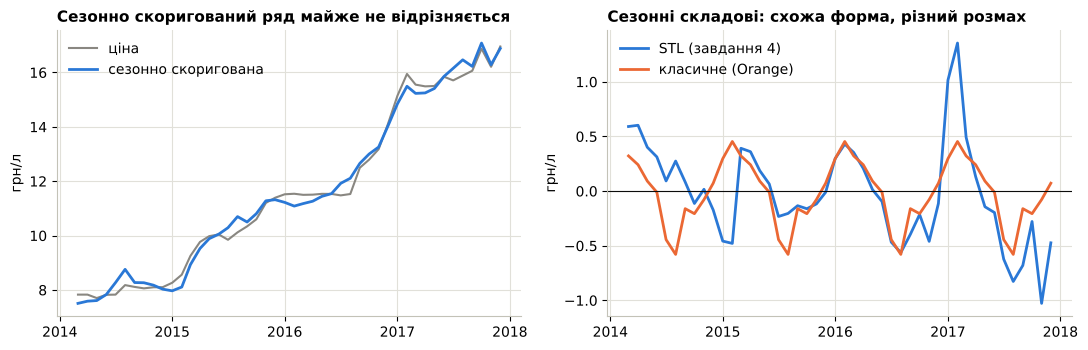

In [15]:
# Завдання 12. Автокореляція та диференціювання — як це рахує Orange
shot('12_correlogram.png', 'Correlogram у Orange (price і Δprice)')
shot('12_seasonal_adjustment.png', 'Сезонно скоригований ряд (Seasonal Adjustment → Line Chart)')

def orange_correlogram(x):
    """Відтворення віджета Correlogram (functions.autocorrelation + owcorrelogram.py):
    ACF до 0.9·n лагів, показуються лише лаги-піки |ACF| (локальні максимуми, order=3),
    межа значущості одна для всіх лагів: 1.96·sqrt((1 + 2·Σr²)/n)."""
    r = acf(x, nlags=int(0.9 * len(x)), fft=True)
    lags = argrelextrema(np.abs(r), np.greater, order=3)[0]
    band = 1.96 * np.sqrt((1 + 2 * (r[lags] ** 2).sum()) / len(x))
    return pd.DataFrame({'лаг': lags, 'ACF': r[lags].round(3), 'значущий': np.abs(r[lags]) > band}), band

# Orange рахує Difference на 46 точках: перша точка NaN, і віджет заповнює її найближчим значенням
d_orange = y.diff()
d_orange.iloc[0] = d_orange.iloc[1]
for name, x in [('price', y), ('Δprice', d_orange)]:
    tab, band = orange_correlogram(x.values)
    sig = tab.loc[tab['значущий'], 'лаг'].tolist()
    print(f'Orange · {name:7s}: показано лаги {tab["лаг"].tolist()} (ACF {tab["ACF"].tolist()}), '
          f'межа ±{band:.3f}, значущі: {sig}')
print('statsmodels (завдання 5): price — значущі ACF', significant_lags(y, 'acf'),
      '| Δprice — значущі ACF', significant_lags(dy, 'acf'))

# Seasonal Adjustment в Orange = класичне розкладання statsmodels (additive, період 12)
cd = seasonal_decompose(y, model='additive', period=12)
adj = y - cd.seasonal                                            # те, що віддає Orange
season_cmp = pd.DataFrame({'STL': S, 'класичне (Orange)': cd.seasonal})
print(f'\nРозмах сезонної складової: STL {S.max() - S.min():.3f}, класичне {cd.seasonal.max() - cd.seasonal.min():.3f} {UNIT}; '
      f'кореляція двох сезонних складових {season_cmp.corr().iloc[0, 1]:.2f}')
print(f'Найбільша різниця між рядом і сезонно скоригованим рядом: {np.abs(y - adj).max():.2f} {UNIT}')
ok = cd.resid.notna()
F_S_cl = max(0.0, 1 - cd.resid[ok].var() / (cd.seasonal[ok] + cd.resid[ok]).var())
print(f'Сила сезонності за класичним розкладанням: F_S = {F_S_cl:.2f} (STL: {F_S:.2f})')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(y.index, y, color=GRAY, lw=1.5, label='ціна')
axes[0].plot(adj.index, adj, color=BLUE, lw=2, label='сезонно скоригована')
axes[0].set_title('Сезонно скоригований ряд майже не відрізняється')
axes[0].legend(frameon=False); axes[0].set_ylabel(UNIT)
axes[1].plot(S.index, S, color=BLUE, lw=2, label='STL (завдання 4)')
axes[1].plot(cd.seasonal.index, cd.seasonal, color=ORANGE, lw=2, label='класичне (Orange)')
axes[1].axhline(0, color=INK, lw=0.8)
axes[1].set_title('Сезонні складові: схожа форма, різний розмах')
axes[1].legend(frameon=False); axes[1].set_ylabel(UNIT)
for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
show(fig, 't12_seasonal_compare')

**Висновок до завдання 12:**

**Корелограма.** Значення ACF однакові — Orange викликає ту саму функцію `statsmodels.acf`. Але показує їх інакше: лише **«піки» |ACF|** (локальні максимуми, до лагу 41) і **одну горизонтальну межу** 1.96·√((1+2Σr²)/n). Тому для `price` на корелограмі один стовпчик — лаг 33 (ACF = −0.45 за межею ±0.34), тоді як statsmodels показує значущі лаги 1–4. Для `Δprice` Orange показує піки на лагах 6, 13, 21, 32, 39, усі в межах ±0.32 — **висновок збігається з завданням 5: після різниці значущих лагів немає**. Для вихідного ряду картини різні не через дані, а через спосіб показу.

**Сезонне коригування.** Seasonal Adjustment в Orange — класичне розкладання (рухоме середнє за 12 місяців + середнє відхилення кожного місяця), а не STL. Скоригований ряд відрізняється від ціни щонайбільше на 0.58 грн/л. Класична сезонна складова схожа за формою на STL (взимку–навесні вище, влітку нижче; кореляція 0.57), але менша: розмах 1.03 проти 2.38 грн/л, F_S = 0.37 проти 0.80. Обидва методи бачать слабку сезонність, а її величина залежить від методу.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

In [16]:
# Завдання 13. Модель і оцінювання в Orange
shot('13_model_evaluation.png', 'Model Evaluation: 7 фолдів × 3 кроки')
shot('13_error_20_folds.png', 'Model Evaluation з типовими 20 фолдами × 3 кроки')

# Звідки помилка: у functions.model_evaluation є перевірка  n_folds·steps + max_lag ≤ довжина ряду,
# де max_lag = max(p, d, q) = 1 для ARIMA(1,1,1)
max_lag = max(ORDER)
for folds in (20, N_FOLDS):
    need = folds * H + max_lag
    print(f'{folds:2d} фолдів × {H} кроки: потрібно {folds} · {H} + {max_lag} = {need} точок, '
          f'у ряді {len(y)} → {"ПОМИЛКА" if need > len(y) else "OK"}')
print(f'Найбільше фолдів по {H} кроки для нашого ряду: {(len(y) - max_lag) // H}')

# Які відрізки перевіряє Orange: fold = 1…7, навчання до позиції −3·fold (від найсвіжішого до найстарішого)
rows = []
for fold in range(1, N_FOLDS + 1):
    end = len(y) - H * fold
    rows.append([fold, f'{grid[0]:%m.%Y}–{grid[end-1]:%m.%Y}', end, f'{grid[end]:%m.%Y}–{grid[end+H-1]:%m.%Y}'])
print()
print(pd.DataFrame(rows, columns=['fold в Orange', 'навчання', 'точок', 'прогноз']).to_string(index=False))

[знімок ще не додано: orange/13_model_evaluation.png] — Model Evaluation: 7 фолдів × 3 кроки
[знімок ще не додано: orange/13_error_20_folds.png] — Model Evaluation з типовими 20 фолдами × 3 кроки
20 фолдів × 3 кроки: потрібно 20 · 3 + 1 = 61 точок, у ряді 46 → ПОМИЛКА
 7 фолдів × 3 кроки: потрібно 7 · 3 + 1 = 22 точок, у ряді 46 → OK
Найбільше фолдів по 3 кроки для нашого ряду: 15

 fold в Orange        навчання  точок         прогноз
             1 03.2014–09.2017     43 10.2017–12.2017
             2 03.2014–06.2017     40 07.2017–09.2017
             3 03.2014–03.2017     37 04.2017–06.2017
             4 03.2014–12.2016     34 01.2017–03.2017
             5 03.2014–09.2016     31 10.2016–12.2016
             6 03.2014–06.2016     28 07.2016–09.2016
             7 03.2014–03.2016     25 04.2016–06.2016


**Висновок до завдання 13:**

**Model Evaluation, 7 фолдів × 3 кроки** (рядок без «(in-sample)»): RMSE 0.455, MAE 0.270, MAPE 0.024, POCID 65.0 — знімок 13.1.

**Типові 20 × 3:** Orange відмовляється рахувати й пише *«Supplied time series is too short for this many folds / step size. Retry with fewer iterations.»* Це перевірка у `functions.model_evaluation`: потрібно `n_folds · steps + max_lag ≤ довжина ряду`, де `max_lag = max(p, d, q) = 1`. Для 20 × 3 треба 20·3 + 1 = **61** точка, а в ряді **46**. Для 7 × 3 — 22, тож усе гаразд. Найбільше для нашого ряду — 15 фолдів по 3 кроки.

**Які фолди:** fold 1 навчається на 03.2014–09.2017 (43 точки) і прогнозує 10–12.2017; fold 2 — до 06.2017, прогноз 07–09.2017; … fold 7 — на 03.2014–03.2016 (25 точок), прогноз 04–06.2016. Це ті самі 7 відрізків, що й у Частині 1, лише в зворотному порядку — від найсвіжішого.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [17]:
# Завдання 14. Чому числа не збігаються
# 1) Відтворюємо цикл functions.model_evaluation з Orange: fold = 1…7, прогнози склеюються
#    від найсвіжішого фолду до найстарішого (порядок важливий лише для POCID).
full_true, full_pred = [], []
for fold in range(1, N_FOLDS + 1):
    train_end = -fold * H
    full_true.extend(v[train_end:][:H])
    full_pred.extend(arima_fc(v[:train_end], H))
full_true, full_pred = np.array(full_true), np.array(full_pred)
# ті самі 21 прогноз, що й у завданні 7, лише фолди в зворотному порядку
assert np.allclose(full_pred, np.concatenate([arima_pred[3 * (N_FOLDS - f):3 * (N_FOLDS - f) + 3] for f in range(1, N_FOLDS + 1)]))

# 2) Формули з orangecontrib/timeseries/functions.py
def o_rmse(t, p):  return np.sqrt(np.sum((t - p) ** 2) / len(p))
def o_mae(t, p):   return np.median(np.abs(t - p))                       # МЕДІАНА, хоч і зветься MAE
def o_mape(t, p):  return np.mean(np.abs(t - p)) / np.abs(t).mean()      # частка, не відсотки
def o_pocid(t, p): return 100 * np.mean((np.diff(t) * np.diff(p)) > 0)

# 3) Значення з таблиці Model Evaluation (рядок без «(in-sample)»), знімок 13_model_evaluation.png
# Зараз тут очікувані значення (пораховані за кодом Orange). ЗВІР зі своїм знімком і за потреби виправ!
ORANGE = {'RMSE': 0.4548, 'MAE': 0.2697, 'MAPE': 0.0240, 'POCID': 65.0}

py_orange = {'RMSE': o_rmse(full_true, full_pred), 'MAE': o_mae(full_true, full_pred),
             'MAPE': o_mape(full_true, full_pred), 'POCID': o_pocid(full_true, full_pred)}
py_part1 = {'RMSE': arima_m['RMSE'], 'MAE': arima_m['MAE'], 'MAPE': arima_m['MAPE, %'], 'POCID': np.nan}
formula = {'RMSE': 'sqrt(Σe² / n)', 'MAE': 'median|e|  (медіана!)',
           'MAPE': 'mean|e| / mean|y|  (частка)', 'POCID': '100·частка пар, де Δy і Δŷ одного знака'}

tab14 = pd.DataFrame({'Orange': ORANGE, 'Python за формулою Orange': py_orange,
                      'Python, Частина 1': py_part1, 'формула Orange': formula})
print(tab14.to_string(float_format=lambda x: f'{x:.4f}'))
if all(val is not None for val in ORANGE.values()):
    ok = {k: bool(abs(ORANGE[k] - py_orange[k]) < 1e-3) for k in ORANGE}
    print('\nЗбіг до третього знака:', ', '.join(f'{k} — {"так" if v else "НІ"}' for k, v in ok.items()))
    assert all(ok.values()), 'розбіжність — перевір дані й налаштування Orange'
else:
    print('\nВпиши значення з таблиці Orange у словник ORANGE, щоб перевірити збіг.')

e = full_true - full_pred
print(f'\nMAE: середнє |e| = {np.mean(np.abs(e)):.4f}, медіана |e| = {np.median(np.abs(e)):.4f} '
      f'— різниця у {np.mean(np.abs(e)) / np.median(np.abs(e)):.1f} раза')
print(f'MAPE: середнє |e/y|·100 = {np.mean(np.abs(e / full_true)) * 100:.3f} %, '
      f'Orange = {o_mape(full_true, full_pred):.5f} (частка) = {o_mape(full_true, full_pred) * 100:.3f} %')

       Orange  Python за формулою Orange  Python, Частина 1                           формула Orange
RMSE   0.4548                     0.4548             0.4548                            sqrt(Σe² / n)
MAE    0.2697                     0.2697             0.3438                    median|e|  (медіана!)
MAPE   0.0240                     0.0240             2.3082              mean|e| / mean|y|  (частка)
POCID 65.0000                    65.0000                NaN  100·частка пар, де Δy і Δŷ одного знака

Збіг до третього знака: RMSE — так, MAE — так, MAPE — так, POCID — так

MAE: середнє |e| = 0.3438, медіана |e| = 0.2697 — різниця у 1.3 раза
MAPE: середнє |e/y|·100 = 2.308 %, Orange = 0.02396 (частка) = 2.396 %


**Висновок до завдання 14:**

| метрика | Orange | Python за формулою Orange | Python, Частина 1 | формула Orange |
|---|---|---|---|---|
| RMSE | 0.455 | 0.4548 | 0.4548 | √(Σe²/n) |
| MAE | 0.270 | 0.2697 | 0.3438 | **median** \|e\| |
| MAPE | 0.024 | 0.0240 | 2.308 % | mean\|e\| / mean\|y\| (частка) |
| POCID | 65.0 | 65.0 | — | 100 · частка пар, де Δy і Δŷ одного знака |

**Не відповідає своїй назві — MAE:** в Orange це **медіана** абсолютної похибки, а MAE зазвичай означає **середнє**. Медіана ігнорує кілька великих промахів, тому 0.270 замість 0.344 (у 1.3 раза менше). MAPE теж «інший»: Orange ділить середню похибку на середню ціну й подає **частку** (0.024), а звичне MAPE — середнє відносних похибок у **відсотках** (2.31 %; навіть у відсотках формула Orange дала б 2.40 %).

**Збіглася одразу — RMSE** (0.4548): формула однакова, а прогнози однакові, бо віджет ARIMA — обгортка над тим самим `statsmodels` ARIMA на тих самих даних і фолдах.

**Висновок:** перш ніж порівнювати числа двох інструментів, перевір: ті самі дані, ту саму схему перевірки (фолди, горизонт, порядок), ту саму модель — і **точні формули метрик та одиниці** (частка чи відсотки). Однакова назва не гарантує однакову формулу.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [18]:
# Завдання 15. Матриця напрямку зміни
up_true = np.sign(np.diff(full_true))      # що сталося насправді: +1 зросла, −1 впала
up_pred = np.sign(np.diff(full_pred))      # що передбачила модель
lab = {1.0: 'зросла', -1.0: 'впала', 0.0: 'не змінилась'}
mat = pd.crosstab(pd.Series(up_true).map(lab).rename('насправді'),
                  pd.Series(up_pred).map(lab).rename('модель передбачила'))
order = [k for k in ['зросла', 'впала', 'не змінилась'] if k in mat.index or k in mat.columns]
mat = mat.reindex(index=order, columns=order, fill_value=0)   # порядок як у завданні: зросла / впала
print('Матриця напрямку (20 пар сусідніх значень, як у POCID Orange):')
print(mat.to_string())
correct = np.mean(up_true * up_pred > 0) * 100
print(f'Частка правильних напрямків: {correct:.1f} %  |  POCID: {py_orange["POCID"]:.1f}')
assert np.isclose(correct, py_orange['POCID'])
inside = np.array([i % H != H - 1 for i in range(len(full_true) - 1)])   # пари всередині одного фолду
print(f'Із 20 пар {np.sum(~inside)} — «стики» різних фолдів; лише по {inside.sum()} парах усередині фолдів '
      f'частка правильних = {np.mean((up_true * up_pred > 0)[inside]) * 100:.1f} %')

# Увага: Orange склеює фолди від найсвіжішого до найстарішого, тому 6 із 20 пар — це стрибки
# між різними фолдами (напр., 12.2017 → 07.2017). Чесніше питання для покупця інше:
# «чи буде ціна через h місяців ВИЩОЮ за поточну (останню відому)?»
last_known = np.concatenate([np.repeat(v[a - 1], b - a) for a, b in FOLDS])
real = np.where(test_y > last_known, 'вища', 'не вища')
said = np.where(arima_pred > last_known, 'вища', 'не вища')
dec = pd.crosstab(pd.Series(real, name='насправді через h міс.'), pd.Series(said, name='модель каже'))
print('\nРішення «купувати зараз чи чекати» (21 прогноз, порівняння з останньою відомою ціною):')
print(dec.to_string())
print(f'Влучань: {np.mean(real == said) * 100:.1f} %; частка місяців, коли ціна справді виросла: '
      f'{np.mean(real == "вища") * 100:.1f} %')

Матриця напрямку (20 пар сусідніх значень, як у POCID Orange):
модель передбачила  зросла  впала
насправді                        
зросла                   6      5
впала                    2      7
Частка правильних напрямків: 65.0 %  |  POCID: 65.0
Із 20 пар 6 — «стики» різних фолдів; лише по 14 парах усередині фолдів частка правильних = 50.0 %

Рішення «купувати зараз чи чекати» (21 прогноз, порівняння з останньою відомою ціною):
модель каже             вища  не вища
насправді через h міс.               
вища                      11        5
не вища                    1        4
Влучань: 71.4 %; частка місяців, коли ціна справді виросла: 76.2 %


**Висновок до завдання 15:**

| насправді \ модель передбачила | зросла | впала |
|---|---|---|
| **зросла** | 6 | 5 |
| **впала** | 2 | 7 |

Правильних 6 + 7 = 13 із 20 = **65 %** — збігається з POCID Orange ✔.

Але 6 із 20 пар — «стики» фолдів: Orange склеює прогнози від найсвіжішого фолду до найстарішого і, наприклад, порівнює 12.2017 з 07.2017. По 14 справжніх парах усередині фолдів модель вгадує напрямок лише в **50 %** — як монетка.

**Для рішення «купувати зараз чи чекати»** доречніше питання: чи буде ціна через h місяців вищою за поточну? Модель відповідає правильно у 71 % випадків, але проста порада «ціна росте — купуй зараз» права у 76 % (ціна справді зросла в 16 із 21 випадку). Отже, **для цього рішення модель не корисна**.

**Чому це інше питання, ніж MAE/RMSE:** MAE і RMSE міряють, **на скільки гривень** помиляємося, а матриця — чи вгадали **знак** зміни. Модель може бути точною за величиною (похибка 0.34 грн), але плутати напрямок, коли ціна майже стоїть, — і навпаки.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

1. **Сезонність є, але слабка.** STL дає F_S = 0.80 > 0.3, класичне розкладання — 0.37 > 0.3; 80 % подорожчання припало на вересень–лютий, а в травні–липні ціна майже стоїть. Водночас на 46 точках навіть шум дає F_S ≈ 0.6, тож доказ слабкий.
2. **Найкращий базис — дрейф** (MAE 0.481 грн/л). ARIMA(1,1,1) перевершила і його, і наївний на 29–32 % (MAE 0.344), хоча за ACF/PACF я обрав би ARIMA(0,1,0), тобто сам наївний прогноз.
3. **Точка зміни** — з 01.2017 (10.11 → 15.93 грн/л, t = 16.6), але перестановковий тест дає p = 0.074, тож вона не значуща. У часі вона збігається з подвоєнням мінімальної зарплати з 1 січня 2017 р., але це збіг, а не доведена причина.
4. **Метрики різні, бо формули різні:** MAE в Orange — медіана (0.270 проти 0.344), MAPE — mean|e|/mean|y| і частка (0.024 проти 2.31 %). RMSE з однаковою формулою збіглася до знака (0.455), а POCID (65 %) рахує ще й штучні пари на стиках фолдів.
5. **Через 46 спостережень не вдалося:** надійно довести сезонність і її форму (лише ~4 цикли, STL і класичне розкладання розходяться), довести значущість точки зміни, перевірити модель більш ніж на 21 місяці (максимум 15 фолдів) і спробувати сезонні моделі на кшталт SARIMA.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude (Anthropic), модель Claude Opus 5.5, жовтень 2026 |
| Для яких саме завдань | Усі 15: код Частини 1; відтворення формул Orange за вихідним кодом додатка Timeseries (`functions.py`); тексти висновків; звіт |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | Код, тексти висновків, пояснення понять, рецензія (завдання 9), заготовка потоку Orange |
| Що ви змінили у згенерованому результаті й чому | ✎ *допиши сам: що змінив і чому (або «нічого не змінював»)* |
| Що з отриманого ви **перевірили самостійно** і яким способом | ✎ *підтвердь: зошит виконано в Colab командою Restart & Run All без помилок; числа таблиці Model Evaluation в Orange збіглися з відтворенням у Python до 3-го знака* |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | ✎ *допиши сам (якщо не помітив — «не помітив»)* |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ______________________  Дата: ______________